# Sparse movie rating prediction

**Barda Soltani Moakhar and Setayesh Heydari**  
Linear Algebra | Instructor: **Maryam Ramezani**

We learn low-rank user and movie factors from observed MovieLens ratings. The model includes global, user, and item biases. Missing entries do not enter the training loss.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "laml").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "laml").exists():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
RECOMPUTE = False

def read_result(name):
    return json.loads((ROOT / "results" / name).read_text())

def show_figure(name):
    from PIL import Image
    display(Image.open(ROOT / "results" / "figures" / name))

In [2]:
if RECOMPUTE:
    from laml.experiments import run
    run("recommender")
metrics = read_result("recommender_metrics.json")
display(pd.DataFrame([metrics]).T.rename(columns={0:"Value"}))

,Value
seed,42
ratings,100836
users,610
rated_movies,9724
catalog_movies,9742
density,0.017
train,80668
validation,10084
test,10084
rank,20


## Observed-entry factorization

The predictor is $\hat r_{ui}=\mu+b_u+c_i+p_u^Tq_i$. SGD minimizes squared residuals plus a per-observation L2 penalty. Copies of both old factor vectors are used for simultaneous updates.

Ordinary truncated SVD solves a complete-matrix approximation problem. This regularized observed-entry objective is different. Filling unknown ratings with zero would add artificial low ratings.

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


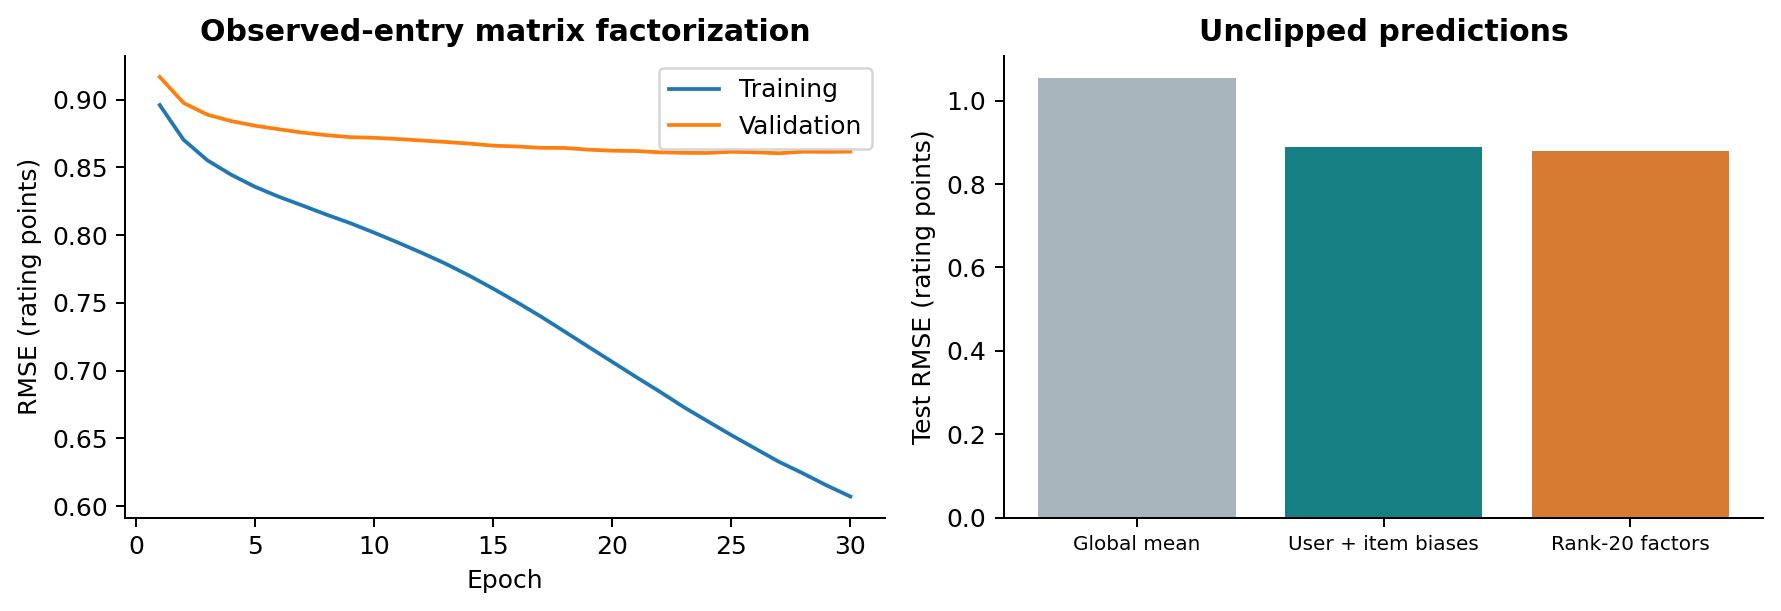

Ratings: 100836
Users: 610
Rated movies: 9724


In [3]:
ratings = pd.read_csv(ROOT / "data/raw/movielens/ratings.csv")
print("Ratings:", len(ratings))
print("Users:", ratings["userId"].nunique())
print("Rated movies:", ratings["movieId"].nunique())
display(ratings.head())
show_figure("recommendation.png")

## Held-out evaluation

A random 80/10/10 rating split separates training, validation, and test observations. Validation chooses the epoch. The bias-only baseline is fitted by a sparse regularized least-squares solve. Metrics below use raw, unclipped predictions.

In [4]:
predictions = pd.read_csv(ROOT / "results/rating_test_predictions.csv")
rmse = np.sqrt(np.mean((predictions["rating"]-predictions["prediction"])**2))
print(f"Recomputed test RMSE: {rmse:.6f}")
assert np.isclose(rmse, metrics["factor_test_rmse"])
display(pd.DataFrame({"Model":["Global mean","User + item biases","Rank-20 factors"], "Test RMSE":[metrics["global_mean_test_rmse"],metrics["bias_only_test_rmse"],metrics["factor_test_rmse"]]}))

,Model,Test RMSE
0,Global mean,1.054474
1,User + item biases,0.889582
2,Rank-20 factors,0.879141


Recomputed test RMSE: 0.879141


## Recommendations with original identifiers

The showcase uses original MovieLens userId 201. It excludes every movie rated by that user in the supplied snapshot and limits candidates to films with at least 20 training ratings. Ordering uses the raw model score; the display rating is clipped to the valid range.

In [5]:
recommendations = pd.read_csv(ROOT / "results/recommendations_user_201.csv")
seen = set(ratings.loc[ratings["userId"]==201,"movieId"])
assert not (set(recommendations["movieId"]) & seen)
display(recommendations[["movieId","title","genres","predicted_rating"]])

,movieId,title,genres,predicted_rating
0,541,Blade Runner (1982),Action|Sci-Fi|Thriller,5.000000
1,5902,Adaptation (2002),Comedy|Drama|Romance,5.000000
2,778,Trainspotting (1996),Comedy|Crime|Drama,5.000000
3,1212,"Third Man, The (1949)",Film-Noir|Mystery|Thriller,4.947222
4,56782,There Will Be Blood (2007),Drama|Western,4.933688
5,1262,"Great Escape, The (1963)",Action|Adventure|Drama|War,4.931205
6,1252,Chinatown (1974),Crime|Film-Noir|Mystery|Thriller,4.903374
7,912,Casablanca (1942),Drama|Romance,4.902797
8,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.886211
9,1204,Lawrence of Arabia (1962),Adventure|Drama|War,4.864164


## Limits

Random rating splits mix time periods. RMSE measures rating prediction rather than ranking quality. The popularity threshold and known-history exclusion are for the illustrative list; they are not a top-k benchmark. Cold-start results are reported separately. A temporal split and ranking metrics would be necessary to evaluate a deployed recommender.